### Parameters and Protocol

Neurons given autapses of various strengths (e = 0.2ms^-1, tau = 2.0 ms). 

Injected with a 60pA driving current and a positive step is injected at the half way point (1500ms). 

FLUSS algorithm is used directly on the membrane potential recording to try and estimate the change point time.

These estimates and the 'confidence' (CAC) are plotted below.

In [1]:
import aqua

from aqua.batchAQUA_general import batchAQUA
from aqua.utils import *
from aqua.stimulus import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import convolve, windows
import scipy.stats as stats
from tqdm import tqdm
import pickle
import seaborn as sns
sns.set_theme()

from CPA_with_AQUA import *

In [2]:
#outfile = 'CPA_joblibTest_data.pickle'
tag = 'N100'
outfile = f'CPA_cusum_{tag}_llr_pair.pickle'
SAVE = False

true_cp = 5000

with open(outfile, 'rb') as file:
    data = pickle.load(file)

print(data.head())

print("- - - - - -")
# Need to average the output over trials...


variances = data['variance'].unique()
autapse_f = data['autapse f'].unique()
trial_num = data['N'].unique()

N_neurons = len(autapse_f)
N_noise = len(variances)
N_trials = len(trial_num)

print(f"f: {N_neurons}")
print(f"var: {N_noise}")
print(f"N: {N_trials}")

   N  variance  step_height  autapse f  ISI window     score  change point  \
0  0       0.0            0          0         NaN  0.025578        8835.0   
1  1       0.0            0          0         NaN  0.025578        8835.0   
2  2       0.0            0          0         NaN  0.025578        8835.0   
3  3       0.0            0          0         NaN  0.025578        8835.0   
4  4       0.0            0          0         NaN  0.025578        8835.0   

     method   pre dist  post dist  score per s  divergence  divergence per s  
0  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
1  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
2  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
3  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
4  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
- - - - - -
f: 11
var: 5
N: 100


   autapse f  variance  N        AUC
0          0       0.0  0  19.800256
1          0       0.0  1  19.800256
2          0       0.0  2  19.800256
3          0       0.0  3  19.800256
4          0       0.0  4  19.800256


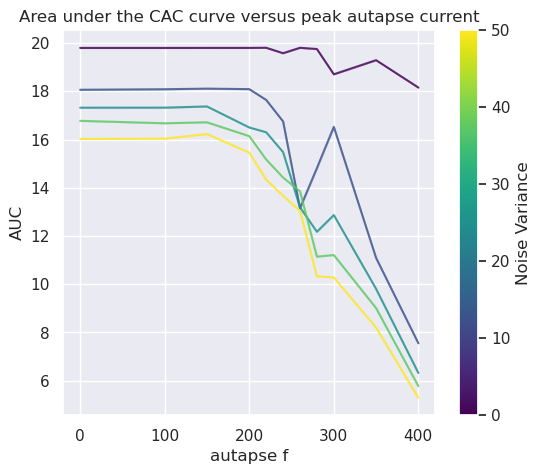

In [3]:
## Try to calculate the area under each curve
step_heights = data['step_height'].unique()

max_area = np.trapezoid(y = np.ones(len(step_heights)), x = step_heights)

df_data = []
for i, v in enumerate(variances):
    for j, f in enumerate(autapse_f):
        mean_CAC = np.zeros(len(step_heights))
        for n in trial_num:
            # loop over every repeat trial

            # get CAC data and calculate the area under the CAC curve
            sub_df = data[(data['variance'] == v) & (data['autapse f'] == f) & (data['N'] == n)]
            cac_arr = sub_df['score']
            # calculate the normalized area under the curve.
            AUC = np.trapezoid(y = cac_arr, x = step_heights)/max_area

            #temp_df = pd.DataFrame(data = [[f, v, n, AUC]])
            #df = pd.concat([df, temp_df], axis = 0, ignore_index = True)
            row_dict = {
                'autapse f': f,
                'variance': v,
                'N': n,
                'AUC': AUC
            }
            df_data.append(row_dict)

df = pd.DataFrame(df_data)
print(df.head())

fig, ax = plt.subplots(1, 1, figsize = (6, 5))
cmap_name = 'viridis'
norm = mcolors.Normalize(vmin=data['variance'].min(), vmax=data['variance'].max())

sns.lineplot(data = df, x = 'autapse f', y = 'AUC', hue = 'variance', palette = cmap_name, ax = ax, 
            legend = False, estimator = 'mean', errorbar = ('ci', 0.9), err_style = 'band', alpha = 0.8)

#ax.set_ylim((0, 10))
ax.set_title('Area under the CAC curve versus peak autapse current')

# add colorbar
sm = cm.ScalarMappable(cmap=cmap_name, norm=norm)
sm.set_array([])  # Dummy array for the mappable

# Add the colorbar to the figure
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Noise Variance')

if SAVE: plt.savefig(f'./plots/{tag}_AUC_vs_f.png')

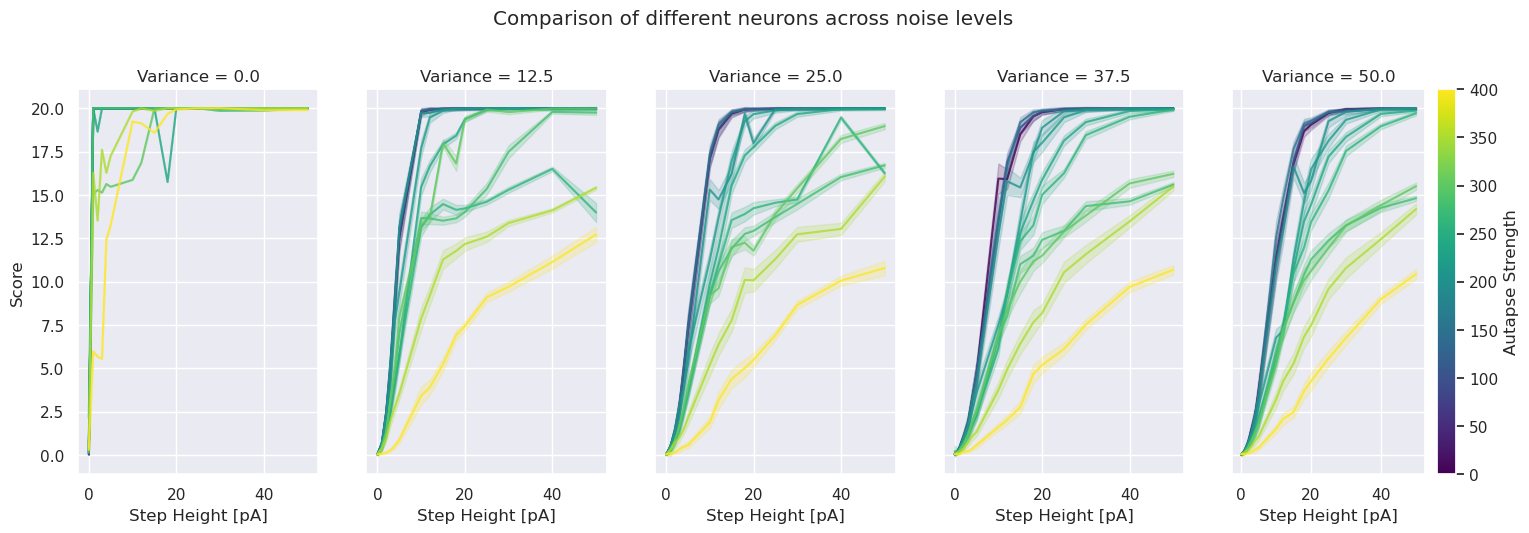

In [4]:
variances = data['variance'].unique()
fig, ax = plt.subplots(1, 5, figsize = (18, 5), sharey = 'row', sharex = 'col')

for n, v in enumerate(variances):
    df = data[(data['variance'] == v)]

    if n == len(variances)-1:
        add_colorbar = True
    else:
        add_colorbar = False

    fig, ax[n] = psychometric_curve(df, x = "step_height", y = "score", hue = "autapse f", fig = fig, ax = ax[n], add_colorbar = add_colorbar)

    #ax[n].set_ylim((0, 10))
    ax[n].set_xlabel('Step Height [pA]')
    ax[n].set_title(f"Variance = {v}")

ax[0].set_ylabel("Score")
fig.suptitle('Comparison of different neurons across noise levels', y = 1.04)

if SAVE: plt.savefig(f'./plots/{tag}_CAC_diff_V.png')

Index(['N', 'variance', 'step_height', 'autapse f', 'ISI window', 'score',
       'change point', 'method', 'pre dist', 'post dist', 'score per s',
       'divergence', 'divergence per s'],
      dtype='object')


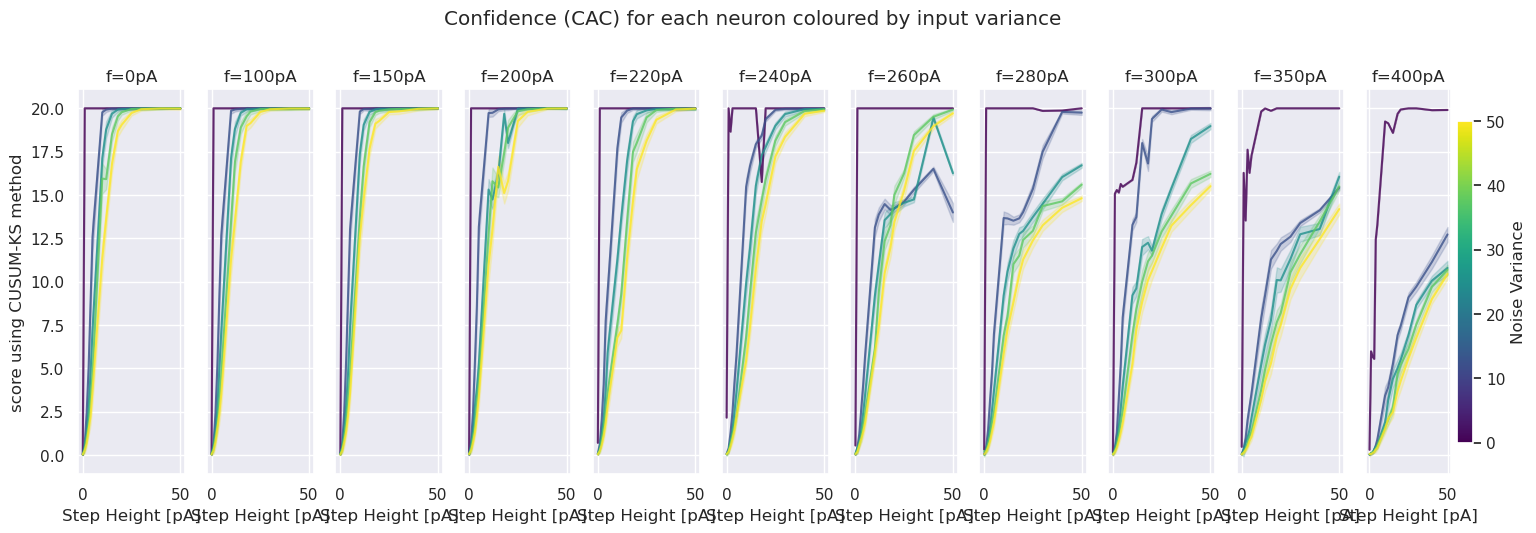

In [5]:
''' PLOT THE SAME NEURON FOR DIFFERENT NOISE LEVELS '''

print(data.keys())

variances = data['variance'].unique()
f_vals = data['autapse f'].unique()


fig, ax = plt.subplots(1, len(f_vals), figsize = (18, 5), sharey = True)

for n, f in enumerate(f_vals):
    
    df = data[(data['autapse f'] == f)]       # get the df for that neuron

    if n == len(f_vals)-1:      # add colorbar to the last axis
        add_colorbar = True
    else:
        add_colorbar = False

    fig, ax[n] = psychometric_curve(df, x = "step_height", y = "score", hue = "variance", fig = fig, ax = ax[n], add_colorbar = add_colorbar, colorbar_label = 'Noise Variance')
    #ax[n].text(0, 0., f'f={np.round(f, 0)}pA')
    #ax[n].set_ylim((0, 1))
    ax[n].set_xlabel('Step Height [pA]')
    ax[n].set_title(f'f={np.round(f, 0)}pA')


ax[0].set_ylabel("score using CUSUM-KS method")
fig.suptitle('Confidence (CAC) for each neuron coloured by input variance', y = 1.04)

if SAVE: plt.savefig(f'./plots/{tag}_CAC_diff_autapse.png')

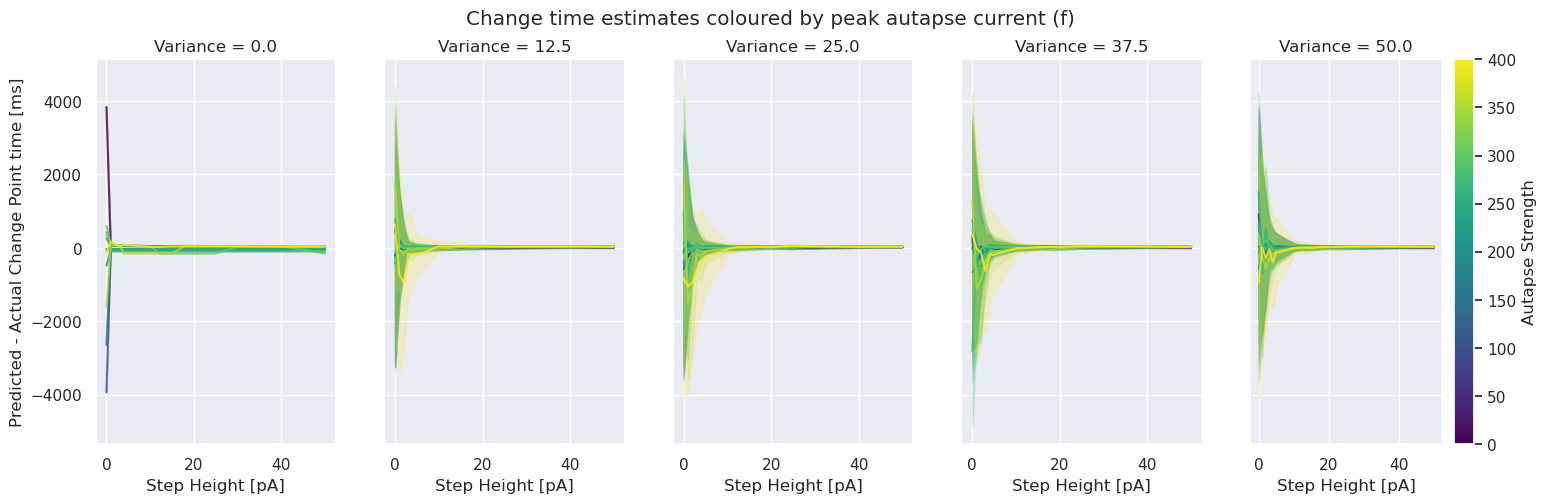

In [6]:
''' TO SUMMARISE CHANGE POINT... '''


variances = data['variance'].unique()
fig, ax = plt.subplots(1, 5, figsize = (18, 5), sharey = 'row', sharex = 'col')

data['delta_CP'] = data['change point'] - true_cp # ms

for n, v in enumerate(variances):
    df = data[(data['variance'] == v)]


    if n == len(variances)-1:
        add_colorbar = True
    else:
        add_colorbar = False

    fig, ax[n] = psychometric_curve(df, x = "step_height", y = "delta_CP", hue = "autapse f", fig = fig, ax = ax[n], add_colorbar = add_colorbar)
    
    ax[n].set_title(f"Variance = {v}")
    ax[n].set_xlabel('Step Height [pA]')

ax[0].set_ylabel("Predicted - Actual Change Point time [ms]")
fig.suptitle('Change time estimates coloured by peak autapse current (f)')

if SAVE: plt.savefig(f'./plots/{tag}_CP_diff_V.png')

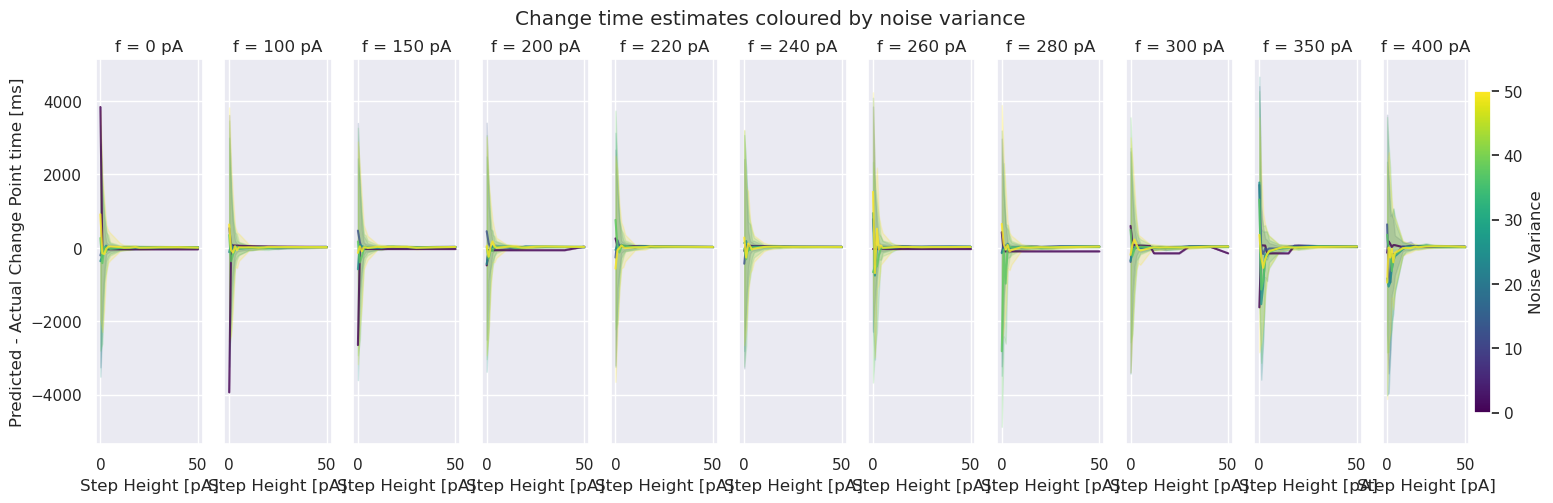

In [7]:
''' TO SUMMARISE CHANGE POINT... '''


f_values = data['autapse f'].unique()
fig, ax = plt.subplots(1, len(f_values), figsize = (18, 5), sharey = 'row', sharex = 'col')

data['delta_CP'] = data['change point'] - true_cp # ms

for n, f in enumerate(f_values):
    df = data[(data['autapse f'] == f)]


    if n == len(f_values)-1:
        add_colorbar = True
    else:
        add_colorbar = False

    fig, ax[n] = psychometric_curve(df, x = "step_height", y = "delta_CP", hue = "variance", fig = fig, ax = ax[n], add_colorbar = add_colorbar, colorbar_label = 'Noise Variance')
    
    ax[n].set_title(f"f = {f} pA")
    ax[n].set_xlabel('Step Height [pA]')

ax[0].set_ylabel("Predicted - Actual Change Point time [ms]")

fig.suptitle('Change time estimates coloured by noise variance')

if SAVE: plt.savefig(f'./plots/{tag}_CP_diff_autapse.png')

Text(0.5, 0.98, 'Change time estimates coloured by noise variance')

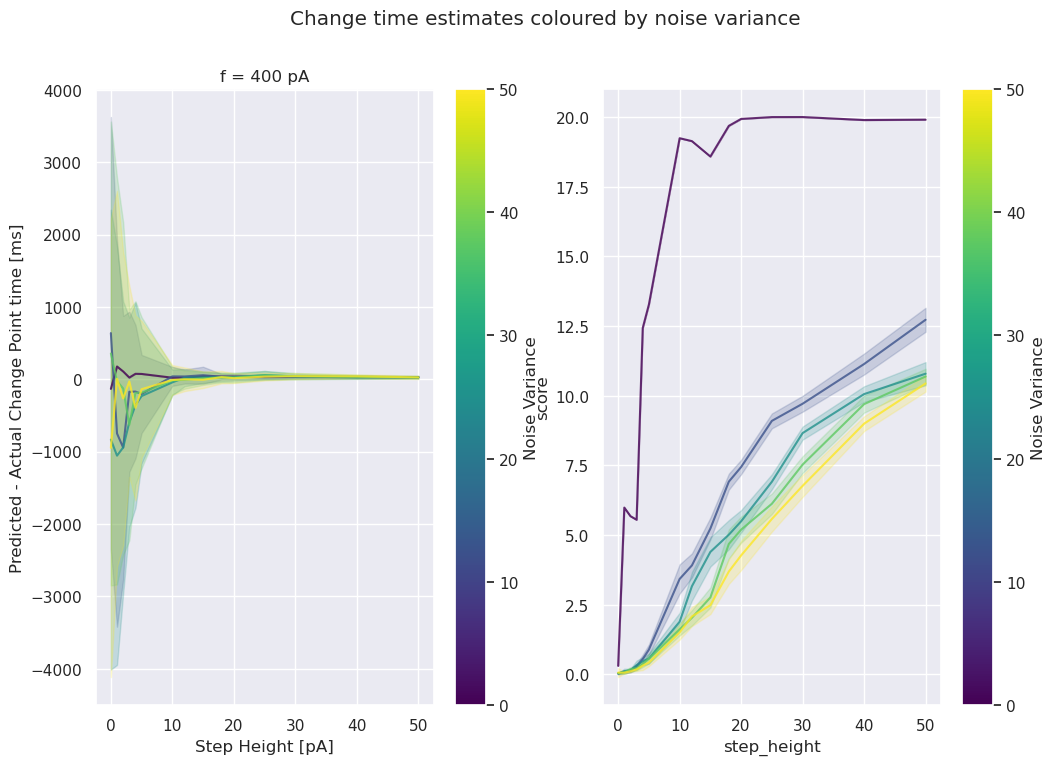

In [8]:
f_values = np.array([400])
fig, ax = plt.subplots(len(f_values), 2, figsize = (12, 8))

data['delta_CP'] = data['change point'] - true_cp # ms

for n, f in enumerate(f_values):
    df = data[(data['autapse f'] == f)]


    if n == len(f_values)-1:
        add_colorbar = True
    else:
        add_colorbar = False

    fig, ax[0] = psychometric_curve(df, x = "step_height", y = "delta_CP", hue = "variance", fig = fig, ax = ax[0], add_colorbar = add_colorbar, colorbar_label = 'Noise Variance')
    fig, ax[1] = psychometric_curve(df, x = "step_height", y = "score", hue = "variance", fig = fig, ax = ax[1], add_colorbar = add_colorbar, colorbar_label = 'Noise Variance')
    
    ax[0].set_title(f"f = {f} pA")
    ax[0].set_xlabel('Step Height [pA]')

ax[0].set_ylabel("Predicted - Actual Change Point time [ms]")
#ax[0].vlines(x = 4, ymin = -1500, ymax = 1000, color = 'red', linestyle = '--', linewidth = 3)

fig.suptitle('Change time estimates coloured by noise variance')


[ 0  1  2  3  4  5 10 12 15 18 20 25 30 40 50]


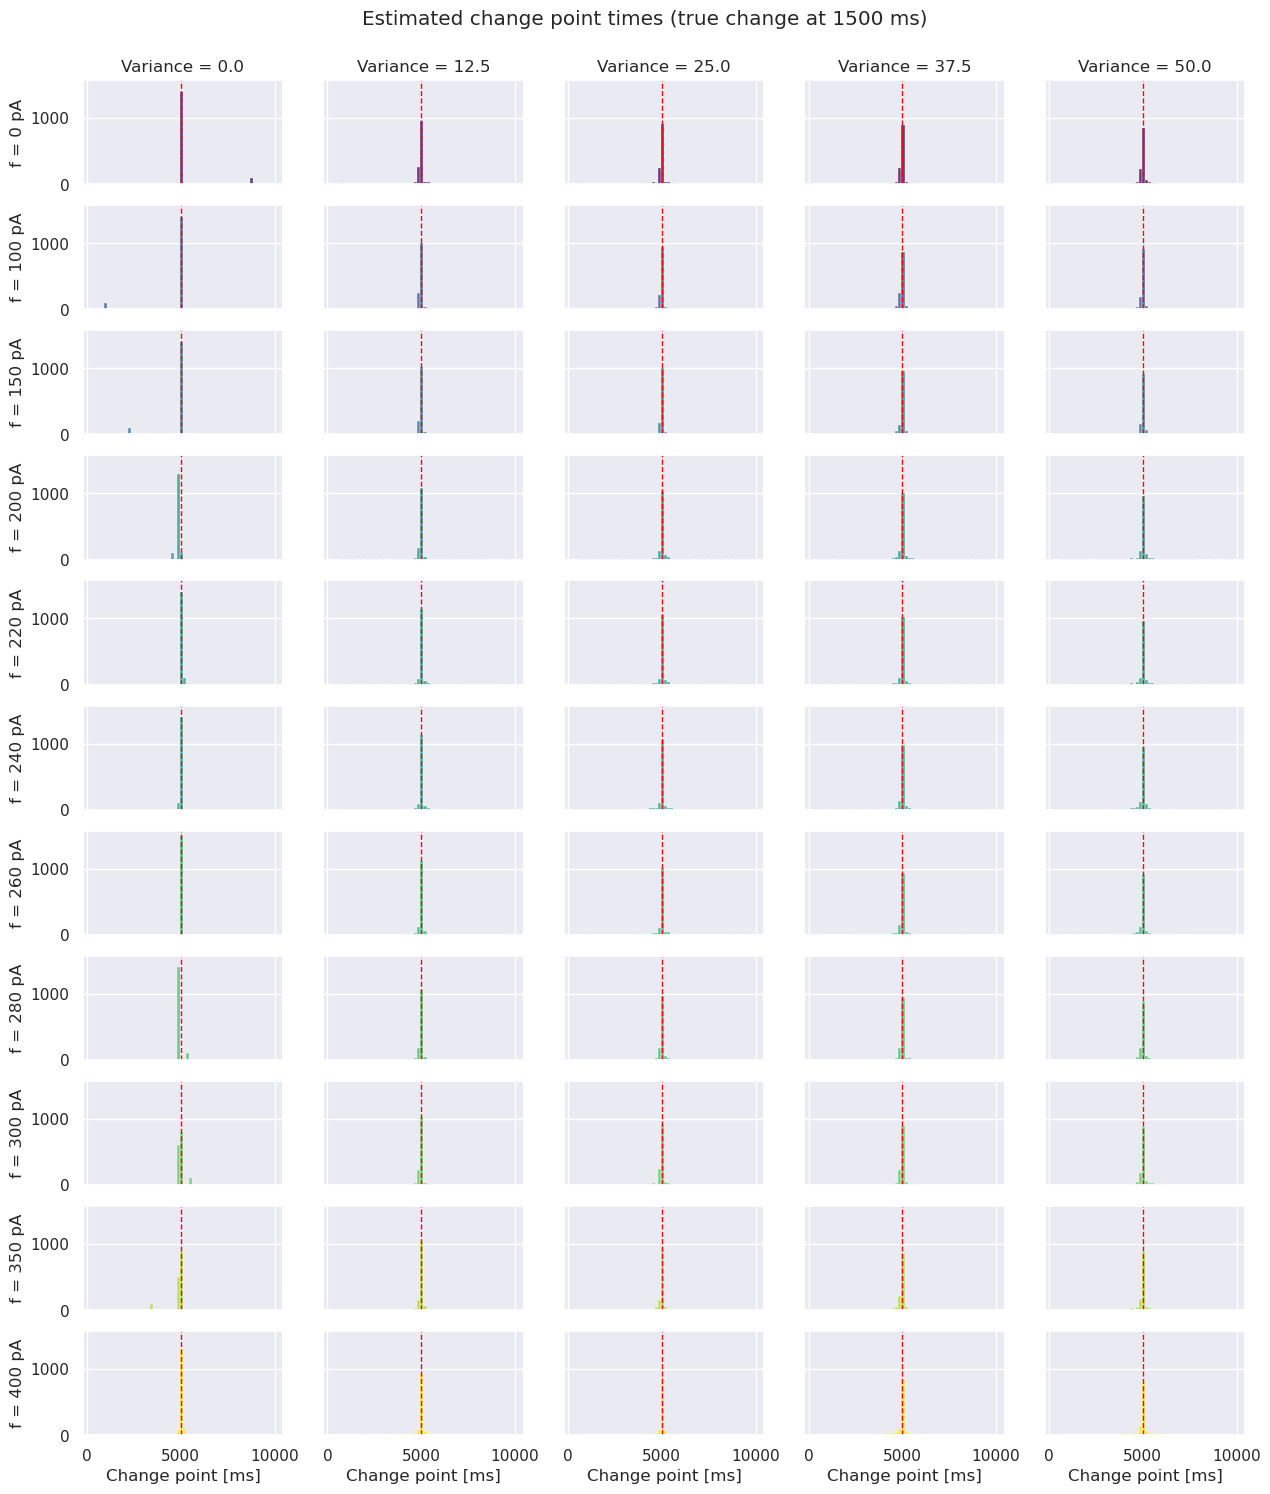

In [9]:
''' HISTOGRAMS OF ESTIMATED CHANGE POINT TIMES '''
# rows = autapse strength, columns = noise variance. Pools all step heights and repeats;
# pass e.g. data[data['step_height'] == 10] to look at a single step height.
print(data['step_height'].unique())
filtered_data = data[data['step_height'] == 20]
fig, ax = changepoint_distribution(data, x = 'change point', row = 'autapse f', col = 'variance', add_colorbar = False, true_cp = true_cp)
fig.suptitle('Estimated change point times (true change at 1500 ms)', y = 0.92)

if SAVE: plt.savefig(f'./plots/{tag}_CP_hist.png', bbox_inches = 'tight')